In [36]:
# 다항회귀로 구현

In [37]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [38]:
#파일 읽어오기
df = pd.read_csv('data/study.csv',sep='\t')
df.head()

,our,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22


In [61]:
#데이터 전처리
data =df.iloc[:,:-1].values   # 처음부터 마지막 컬럼 직전까지의 데이터 (독립 변수 - 원인)
label = df.iloc[:,-1].values  # 마지막 컬럼 데이터 (종속 변수 - 결과)

In [62]:
#데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [63]:
#다항회귀두현- 컬럼 증가
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

#데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(test_poly)
print("예측:",predict)

예측: [-7.76591589 88.86660059 76.11829094  3.73626816 50.26134989]


In [64]:
# 정확도
score= lr.score(train_poly,train_label)
score2= lr.score(test_poly,test_label)
print("train정확도:",score)   #학습데이터
print("test정확도:",score2)   #테스트데이터

train정확도: 0.9851938548998579
test정확도: 0.8121250587972447


In [65]:
# 예측값 입력받기
in_data = input("공부시간을입력하세요. 예)7")
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]])
print(f"공부시간 예측점수:{result[0]:.2f} 점")

공부시간 예측점수:77.05 점


In [66]:
# 구간별 직선을 그리기 위해 범위 정수배열 생성
point = np.arange(0.5,10)
point

array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5])

In [67]:
# lr.coef_ : 다항회귀는 기울기가 2개 나옴, lr.intercept_ : y절편 
print(lr.coef_, lr.intercept_)

[-0.58329547 17.42329379] -16.331738919599758


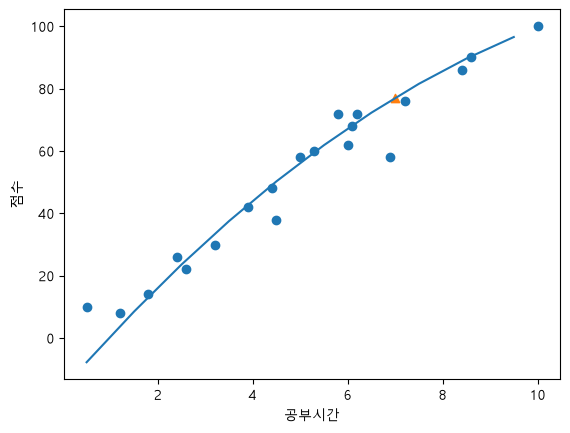

In [68]:
#산점도
plt.scatter(data,label)
plt.scatter(in_data,result,marker="^")

plt.plot(point,point**2*lr.coef_[0]+point*lr.coef_[1]+lr.intercept_)
plt.xlabel("공부시간")
plt.ylabel("점수")
plt.show()